# TP N°1 : Mise en œuvre d'un premier modèle de prévision

**Nom, prénom :** Heni Moemen  
**Niveau :** 1ère année Master  
**Données :** `consommation_batiment.txt` (ou `.csv`) (consommation électrique en kW et température extérieure en °C, données horaires, 15 jours en janvier)

**Plan :** 1. Chargement, contrôle qualité et exploration · 2. Feature engineering · 3. Séparation temporelle · 4. Régression linéaire · 5. Évaluation · 6. Limites du modèle

## Étape 1 : Chargement et exploration des données

### 1.1 Importer les bibliothèques nécessaires

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 4)

### 1.2 Charger le fichier dans un DataFrame

Sous Colab, la cellule ci-dessous ouvre une fenêtre pour téléverser le fichier (`consommation_batiment.txt` ou `.csv`) s'il n'est pas déjà présent.

In [2]:
import os

# Le TP fournit le fichier au format .txt ou .csv (dossier data/ sous VS Code, ou fichier téléversé sous Colab)
candidats = [f for f in ["data/consommation_batiment.txt", "consommation_batiment.txt",
                         "data/consommation_batiment.csv", "consommation_batiment.csv"] if os.path.exists(f)]

# Sous Colab : téléverser le fichier s'il n'existe pas encore
if not candidats:
    try:
        from google.colab import files
        televerse = files.upload()
        candidats = list(televerse.keys())
    except ImportError:
        raise FileNotFoundError("Placez consommation_batiment.txt (ou .csv) dans le dossier du notebook.")

NOM_FICHIER = candidats[0]
print("Fichier utilisé :", NOM_FICHIER)

# sep=None : pandas détecte tout seul le séparateur (virgule, point-virgule, tabulation)
df = pd.read_csv(NOM_FICHIER, sep=None, engine="python")

# Nettoyage des noms de colonnes et conversion de la date
df.columns = df.columns.str.strip()
df["date_heure"] = pd.to_datetime(df["date_heure"])
df = df.sort_values("date_heure").reset_index(drop=True)

# Nom de la colonne cible (consommation) : détecté automatiquement
CIBLE = [c for c in df.columns if "conso" in c.lower()][0]
print("Colonne cible :", CIBLE)

Fichier utilisé : consommation_batiment.txt
Colonne cible : consommation_kw


### 1.3 Premières lignes, informations générales et valeurs manquantes

In [3]:
print("Dimensions du jeu de données :", df.shape)
display(df.head())

Dimensions du jeu de données : (360, 3)


,date_heure,consommation_kw,temperature_c
0,2024-01-15 00:00:00,85.2,2.5
1,2024-01-15 01:00:00,82.1,2.1
2,2024-01-15 02:00:00,78.9,1.8
3,2024-01-15 03:00:00,76.5,1.5
4,2024-01-15 04:00:00,75.3,1.2


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 360 entries, 0 to 359
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   date_heure       360 non-null    datetime64[us]
 1   consommation_kw  360 non-null    float64       
 2   temperature_c    360 non-null    float64       
dtypes: datetime64[us](1), float64(2)
memory usage: 8.6 KB


In [5]:
print("Valeurs manquantes par colonne :")
print(df.isnull().sum())
print()
print("Nombre total de valeurs manquantes :", df.isnull().sum().sum())
display(df.describe())

Valeurs manquantes par colonne :
date_heure         0
consommation_kw    0
temperature_c      0
dtype: int64

Nombre total de valeurs manquantes : 0


,date_heure,consommation_kw,temperature_c
count,360,360.000000,360.000000
mean,2024-01-22 11:30:00,167.785556,3.797500
min,2024-01-15 00:00:00,72.100000,-3.000000
25%,2024-01-18 17:45:00,119.150000,1.800000
50%,2024-01-22 11:30:00,176.100000,3.200000
75%,2024-01-26 05:15:00,205.375000,5.800000
max,2024-01-29 23:00:00,291.800000,10.800000
std,NaN,55.072090,2.911742


### 1.4 Contrôle qualité : détecter et corriger les valeurs fausses

Les données réelles peuvent contenir des erreurs (capteur en panne qui renvoie 0, valeur manquante, température impossible, pic isolé). On les **détecte** avec des règles simples, puis on les **corrige** à partir des valeurs qui les entourent (interpolation entre la valeur précédente et la suivante) ou par la moyenne de la même heure.

| Problème | Règle |
|---|---|
| Date invalide ou en double | ligne supprimée |
| Heure absente | ajoutée puis corrigée |
| Valeur manquante | corrigée |
| Consommation ≤ 0 | corrigée |
| Température hors de −20 à 45 °C | corrigée |
| Température très différente de ses voisines (> 5 °C de la médiane sur 5 h) | corrigée |
| 0 °C exact qui s'écarte de plus de 2 °C de ses voisines | corrigée |
| Consommation très éloignée du profil de cette heure (z-score robuste > 5) | corrigée |

In [6]:
# Règles de contrôle qualité (modifiables)
TEMP_MIN, TEMP_MAX = -20.0, 45.0   # plage plausible de température extérieure (°C)
SAUT_TEMP_MAX = 5.0                # écart maximal toléré entre une température et la médiane de ses voisines (°C)
SAUT_ZERO_MAX = 2.0                # un 0 °C exact est suspect s'il s'écarte de plus de 2 °C de ses voisines
SEUIL_Z = 5.0                      # seuil de détection d'une consommation aberrante (z-score robuste)

# "voisins" : interpolation entre la valeur précédente et la suivante ; "moyenne" : moyenne de la même heure
METHODE_CORRECTION = "voisins"

def auditer_donnees(df, cible):
    """Compte les anomalies présentes dans les données brutes."""
    d = df.copy()
    conso = pd.to_numeric(d[cible], errors="coerce")
    temp = pd.to_numeric(d["temperature_c"], errors="coerce")
    dates = d["date_heure"].dropna()
    grille = pd.date_range(dates.min(), dates.max(), freq="h")
    return {
        "Nombre de lignes": len(d),
        "Période": f"{dates.min()} -> {dates.max()}",
        "Dates invalides": int(d["date_heure"].isna().sum()),
        "Dates en double": int(dates.duplicated().sum()),
        "Heures manquantes": len(grille.difference(dates)),
        "Consommation manquante": int(conso.isna().sum()),
        "Consommation nulle ou négative": int((conso <= 0).sum()),
        "Température manquante": int(temp.isna().sum()),
        f"Température hors de [{TEMP_MIN:.0f}, {TEMP_MAX:.0f}] °C": int(((temp < TEMP_MIN) | (temp > TEMP_MAX)).sum()),
        "Température exactement égale à 0 °C": int((temp == 0).sum()),
    }


def nettoyer_donnees(df, cible, methode="voisins"):
    """
    Détecte et corrige les valeurs fausses.

    Valeurs détectées : manquantes, consommation <= 0, température hors plage,
    température isolée très différente de ses voisines, 0 °C suspect, consommation aberrante
    par rapport au profil habituel de la même heure (jour ouvré / week-end).

    methode = "voisins" : interpolation linéaire entre la valeur précédente et la suivante.
    methode = "moyenne" : moyenne des valeurs de la même heure (même type de jour).

    Retourne le DataFrame corrigé et le tableau des corrections effectuées.
    """
    colonnes = [cible, "temperature_c"]
    d = df.copy()
    rapport = []

    # 1) dates invalides et doublons
    for _ in d.loc[d["date_heure"].isna()].index:
        rapport.append({"date_heure": pd.NaT, "colonne": "ligne", "valeur_avant": np.nan,
                        "valeur_corrigee": np.nan, "raison": "date invalide : ligne supprimée"})
    d = d.dropna(subset=["date_heure"]).sort_values("date_heure")
    doublons = d["date_heure"].duplicated()
    for date in d.loc[doublons, "date_heure"]:
        rapport.append({"date_heure": date, "colonne": "ligne", "valeur_avant": np.nan,
                        "valeur_corrigee": np.nan, "raison": "date en double : ligne supprimée"})
    d = d[~doublons]

    # 2) grille horaire complète : les heures absentes deviennent des valeurs manquantes
    grille = pd.date_range(d["date_heure"].min(), d["date_heure"].max(), freq="h")
    d = d.set_index("date_heure").reindex(grille).rename_axis("date_heure")
    for col in colonnes:
        d[col] = pd.to_numeric(d[col], errors="coerce")

    avant = d[colonnes].copy()
    raisons = {col: pd.Series("", index=d.index) for col in colonnes}
    valeurs = d[colonnes].copy()

    def marquer(col, masque, raison):
        masque = masque.fillna(False) & (raisons[col] == "")
        raisons[col][masque] = raison
        valeurs.loc[raisons[col] != "", col] = np.nan

    # 3) règles de détection
    marquer(cible, valeurs[cible].isna(), "valeur manquante")
    marquer(cible, valeurs[cible] <= 0, "consommation nulle ou négative")
    marquer("temperature_c", valeurs["temperature_c"].isna(), "valeur manquante")
    marquer("temperature_c", (valeurs["temperature_c"] < TEMP_MIN) | (valeurs["temperature_c"] > TEMP_MAX),
            "température hors plage plausible")

    # référence = médiane glissante sur 5 heures (robuste : un pic isolé ne la déforme pas)
    t = valeurs["temperature_c"]
    mediane_voisines = t.rolling(5, center=True, min_periods=3).median()
    ecart = (t - mediane_voisines).abs()
    marquer("temperature_c", ecart > SAUT_TEMP_MAX,
            "température isolée très différente de ses voisines")
    marquer("temperature_c", (t == 0) & (ecart > SAUT_ZERO_MAX),
            "0 °C suspect (valeur par défaut d'un capteur ?)")

    type_jour = (d.index.dayofweek >= 5).astype(int)
    heure = d.index.hour
    c = valeurs[cible]
    profil = c.groupby([type_jour, heure]).transform("median")
    residu = c - profil
    mad = (residu - residu.median()).abs().median() * 1.4826
    if mad > 0:
        z = (residu - residu.median()).abs() / mad
        marquer(cible, z > SEUIL_Z, "consommation aberrante par rapport au profil de cette heure")

    # 4) correction
    for col in colonnes:
        s = valeurs[col]
        if methode == "moyenne":
            moyenne_type = s.groupby([type_jour, heure]).transform("mean")
            moyenne_heure = s.groupby(heure).transform("mean")
            rempli = s.fillna(moyenne_type).fillna(moyenne_heure).fillna(s.mean())
        else:
            rempli = s.interpolate(method="linear", limit_direction="both")
        for date in d.index[raisons[col] != ""]:
            rapport.append({"date_heure": date, "colonne": col, "valeur_avant": avant.loc[date, col],
                            "valeur_corrigee": round(float(rempli.loc[date]), 2), "raison": raisons[col][date]})
        d[col] = rempli

    colonnes_rapport = ["date_heure", "colonne", "valeur_avant", "valeur_corrigee", "raison"]
    return d.reset_index(), pd.DataFrame(rapport, columns=colonnes_rapport)


def graphique_corrections(brut, propre, cible):
    """Compare les données brutes et corrigées (utile quand des valeurs ont été corrigées)."""
    fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
    axes[0].plot(brut["date_heure"], pd.to_numeric(brut[cible], errors="coerce"), "o-", markersize=2, label="brut")
    axes[0].plot(propre["date_heure"], propre[cible], "-", linewidth=1, label="corrigé")
    axes[0].set_ylabel("Consommation (kW)")
    axes[0].legend()
    axes[1].plot(brut["date_heure"], pd.to_numeric(brut["temperature_c"], errors="coerce"), "o-", markersize=2, label="brut")
    axes[1].plot(propre["date_heure"], propre["temperature_c"], "-", linewidth=1, label="corrigé")
    axes[1].set_ylabel("Température (°C)")
    axes[1].legend()
    fig.suptitle("Données brutes et données corrigées")
    fig.tight_layout()
    return fig

In [7]:
# Audit des données brutes
audit = auditer_donnees(df, CIBLE)
for nom, valeur in audit.items():
    print(f"{nom:45s} : {valeur}")

Nombre de lignes                              : 360
Période                                       : 2024-01-15 00:00:00 -> 2024-01-29 23:00:00
Dates invalides                               : 0
Dates en double                               : 0
Heures manquantes                             : 0
Consommation manquante                        : 0
Consommation nulle ou négative                : 0
Température manquante                         : 0
Température hors de [-20, 45] °C              : 0
Température exactement égale à 0 °C           : 3


In [8]:
# Détection et correction des valeurs fausses
df_brut = df.copy()
df, rapport = nettoyer_donnees(df_brut, CIBLE, METHODE_CORRECTION)

if len(rapport) == 0:
    print("Aucune valeur fausse détectée : aucune correction nécessaire.")
else:
    print(f"{len(rapport)} correction(s) effectuée(s) :")
    display(rapport)
    graphique_corrections(df_brut, df, CIBLE)
    plt.show()

Aucune valeur fausse détectée : aucune correction nécessaire.


**Réponse :** les données fournies (`consommation_batiment.txt`) ne contiennent ni valeur manquante, ni consommation nulle, ni doublon, ni heure absente. Les trois températures égales à 0 °C (24 janvier à 2 h, 29 janvier à 4 h et 8 h) sont **cohérentes** : on est en janvier, et elles s'insèrent dans une série qui passe par zéro (par exemple 0,2 puis 0,0 puis −0,2). Elles ne sont donc pas corrigées. Si le fichier utilisé contient des erreurs, elles sont listées dans le tableau ci-dessus avec leur valeur avant et après correction.

### 1.5 Courbe de consommation en fonction du temps

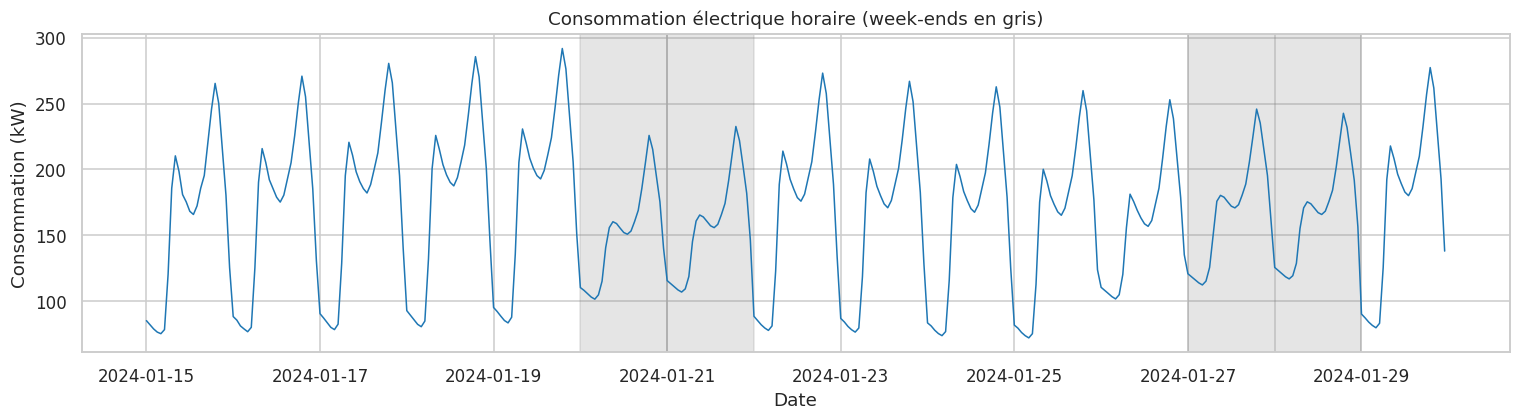

In [9]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(df["date_heure"], df[CIBLE], linewidth=1, color="tab:blue")

# Zones grisées : samedis et dimanches
for jour in pd.date_range(df["date_heure"].min().normalize(), df["date_heure"].max().normalize()):
    if jour.dayofweek >= 5:
        ax.axvspan(jour, jour + pd.Timedelta(days=1), color="grey", alpha=0.2)

ax.set_xlabel("Date")
ax.set_ylabel("Consommation (kW)")
ax.set_title("Consommation électrique horaire (week-ends en gris)")
plt.tight_layout()
plt.show()

Heure de consommation maximale en moyenne : 19 h
Heure de consommation minimale en moyenne : 4 h


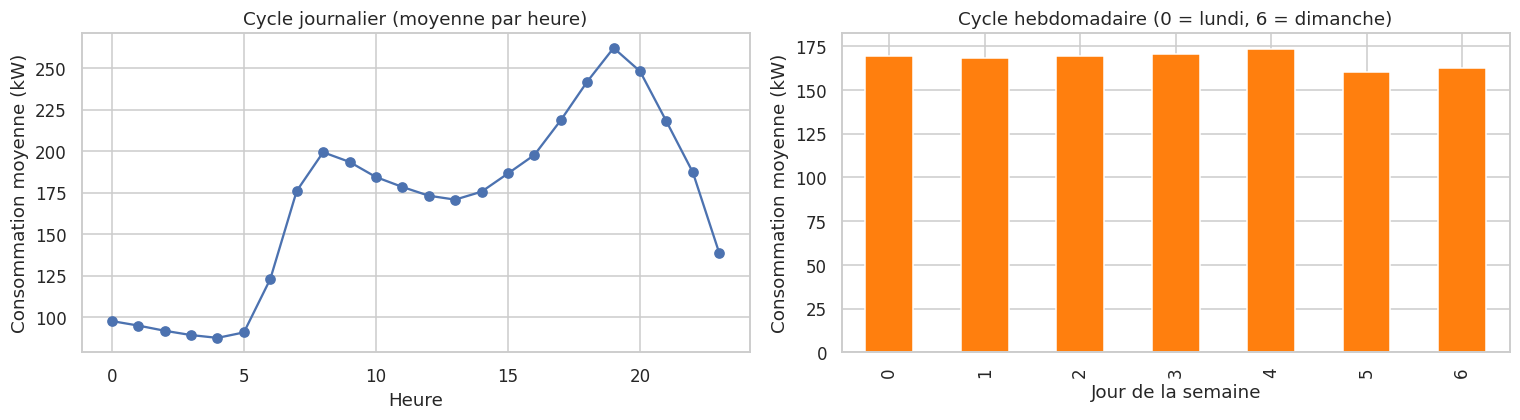

In [10]:
# Cycle journalier : consommation moyenne pour chaque heure de la journée
profil_heure = df.groupby(df["date_heure"].dt.hour)[CIBLE].mean()

# Cycle hebdomadaire : consommation moyenne pour chaque jour (0 = lundi)
profil_jour = df.groupby(df["date_heure"].dt.dayofweek)[CIBLE].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
profil_heure.plot(ax=axes[0], marker="o")
axes[0].set_title("Cycle journalier (moyenne par heure)")
axes[0].set_xlabel("Heure")
axes[0].set_ylabel("Consommation moyenne (kW)")

profil_jour.plot(kind="bar", ax=axes[1], color="tab:orange")
axes[1].set_title("Cycle hebdomadaire (0 = lundi, 6 = dimanche)")
axes[1].set_xlabel("Jour de la semaine")
axes[1].set_ylabel("Consommation moyenne (kW)")
plt.tight_layout()
plt.show()

print("Heure de consommation maximale en moyenne :", profil_heure.idxmax(), "h")
print("Heure de consommation minimale en moyenne :", profil_heure.idxmin(), "h")

**Réponse : que remarque-t-on ?**

- **Cycle journalier :** le profil se répète chaque jour. La consommation est minimale la nuit (creux moyen d'environ 88 kW à 4 h), puis **monte brutalement entre 6 h et 8 h** (d'environ 80 kW à plus de 200 kW) avec l'arrivée des occupants. Elle présente ensuite **deux bosses** : un premier pic le matin (autour de 8 h), un léger creux en début d'après-midi (13 h), puis un **pic du soir plus fort entre 17 h et 20 h** (maximum moyen d'environ 262 kW à 19 h) avant de redescendre.
- **Cycle hebdomadaire :** les week-ends (samedi 20, dimanche 21, samedi 27, dimanche 28 janvier) ont un profil plus plat : la consommation de jour est plus faible (environ 170 kW à 9 h contre 202 kW en semaine) mais celle de la nuit est plus élevée (environ 115 kW contre 85 kW). La moyenne du samedi et du dimanche (environ 160 kW) est inférieure à celle des jours ouvrés (environ 170 kW).
- **Température :** elle varie aussi avec un cycle journalier (plus chaude l'après-midi, plus froide la nuit), ce qui la rend en partie corrélée aux heures, d'où une corrélation directe avec la consommation assez faible (environ 0,25).

## Étape 2 : Feature engineering

### 2.1 Variables calendaires à partir de `date_heure`

- `heure` : 0 à 23
- `jour_semaine` : 0 = lundi, 6 = dimanche
- `est_weekend` : 1 si samedi ou dimanche, 0 sinon

In [11]:
df["heure"] = df["date_heure"].dt.hour
df["jour_semaine"] = df["date_heure"].dt.dayofweek
df["est_weekend"] = (df["jour_semaine"] >= 5).astype(int)

display(df[["date_heure", "heure", "jour_semaine", "est_weekend"]].head(10))

,date_heure,heure,jour_semaine,est_weekend
0,2024-01-15 00:00:00,0,0,0
1,2024-01-15 01:00:00,1,0,0
2,2024-01-15 02:00:00,2,0,0
3,2024-01-15 03:00:00,3,0,0
4,2024-01-15 04:00:00,4,0,0
5,2024-01-15 05:00:00,5,0,0
6,2024-01-15 06:00:00,6,0,0
7,2024-01-15 07:00:00,7,0,0
8,2024-01-15 08:00:00,8,0,0
9,2024-01-15 09:00:00,9,0,0


### 2.2 Variable `temperature2` (température au carré)

Le terme au carré permet au modèle linéaire de représenter un effet **non linéaire** de la température.

In [12]:
df["temperature2"] = df["temperature_c"] ** 2

display(df.head())

,date_heure,consommation_kw,temperature_c,heure,jour_semaine,est_weekend,temperature2
0,2024-01-15 00:00:00,85.2,2.5,0,0,0,6.25
1,2024-01-15 01:00:00,82.1,2.1,1,0,0,4.41
2,2024-01-15 02:00:00,78.9,1.8,2,0,0,3.24
3,2024-01-15 03:00:00,76.5,1.5,3,0,0,2.25
4,2024-01-15 04:00:00,75.3,1.2,4,0,0,1.44


## Étape 3 : Séparation temporelle des données

On **ne mélange pas** les lignes : le modèle apprend sur le passé et est testé sur le futur, comme en situation réelle.

### 3.1 et 3.2 Date de coupure, DataFrames `train` et `test`

In [13]:
date_coupure = pd.Timestamp("2024-01-20")

train = df[df["date_heure"] < date_coupure].copy()
test = df[df["date_heure"] >= date_coupure].copy()

print(f"Entraînement : {len(train)} lignes ({train['date_heure'].min()} -> {train['date_heure'].max()})")
print(f"Test         : {len(test)} lignes ({test['date_heure'].min()} -> {test['date_heure'].max()})")
assert len(train) > 0 and len(test) > 0, "Vérifiez l'année de la date de coupure par rapport aux données."

Entraînement : 120 lignes (2024-01-15 00:00:00 -> 2024-01-19 23:00:00)
Test         : 240 lignes (2024-01-20 00:00:00 -> 2024-01-29 23:00:00)


### 3.3 Matrices de features et vecteurs cibles

On exclut `date_heure` et la cible des features.

In [14]:
features = ["heure", "jour_semaine", "est_weekend", "temperature_c", "temperature2"]

X_train = train[features]
y_train = train[CIBLE]
X_test = test[features]
y_test = test[CIBLE]

print("X_train :", X_train.shape, "| y_train :", y_train.shape)
print("X_test  :", X_test.shape, "| y_test  :", y_test.shape)

X_train : (120, 5) | y_train : (120,)
X_test  : (240, 5) | y_test  : (240,)


## Étape 4 : Entraînement d'un modèle de régression linéaire

In [15]:
# 4.1 et 4.2 : création et entraînement du modèle
modele = LinearRegression()
modele.fit(X_train, y_train)

print("Modèle entraîné sur", len(X_train), "observations")

Modèle entraîné sur 120 observations


### 4.3 Coefficients du modèle

In [16]:
coefficients = pd.DataFrame({
    "variable": features,
    "coefficient": modele.coef_,
    # coefficient x écart-type : permet de comparer des variables d'échelles différentes
    "influence (coef x écart-type)": modele.coef_ * X_train.std().values
})
coefficients["influence absolue"] = coefficients["influence (coef x écart-type)"].abs()

print("Ordonnée à l'origine :", round(modele.intercept_, 3))
display(coefficients.sort_values("influence absolue", ascending=False))

variable_max = coefficients.sort_values("influence absolue", ascending=False).iloc[0]["variable"]
print("Variable la plus influente :", variable_max)

Ordonnée à l'origine : 57.088


,variable,coefficient,influence (coef x écart-type),influence absolue
3,temperature_c,1.759399e+01,47.160979,47.160979
0,heure,6.507002e+00,45.231544,45.231544
4,temperature2,-1.378998e+00,-39.066702,39.066702
1,jour_semaine,1.530004e+00,2.172824,2.172824
2,est_weekend,3.552714e-15,0.000000,0.000000


Variable la plus influente : temperature_c


**Réponse :** la variable la plus influente est **`temperature_c`** (influence d'environ 47), suivie de très près par **`heure`** (environ 45) et de `temperature2` (environ -39). `jour_semaine` a une influence très faible et `est_weekend` a un coefficient **nul**.

On ne compare pas les coefficients bruts : `temperature2` a un petit coefficient mais une très grande échelle (valeurs au carré). Multiplier chaque coefficient par l'écart-type de sa variable donne l'effet d'une variation « typique » de la variable, donc une comparaison équitable.

**Remarque importante :** avec la date de coupure du 20 janvier 2024, les données d'entraînement vont du lundi 15 au vendredi 19, donc **aucun week-end n'est vu pendant l'apprentissage**. `est_weekend` vaut toujours 0 dans `X_train`, son coefficient est donc nul et `jour_semaine` ne peut pas apprendre l'effet du week-end (son coefficient est même légèrement positif, alors que la consommation du week-end est plus basse).

Les signes des coefficients de la température (positif pour `temperature_c`, négatif pour `temperature2`) décrivent une parabole. Ils ne traduisent pas un effet physique du chauffage : le modèle utilise surtout la température pour imiter le cycle journalier, puisque la température suit elle-même l'heure de la journée.

## Étape 5 : Évaluation sur les données de test

### 5.1 et 5.2 Prédictions et métriques MAE, RMSE, MAPE

In [17]:
# 5.1 : prédictions sur le jeu de test
y_pred = modele.predict(X_test)

# 5.2 : métriques
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100   # en pourcentage

print(f"MAE  : {mae:.2f} kW")
print(f"RMSE : {rmse:.2f} kW")
print(f"MAPE : {mape:.2f} %")

MAE  : 29.43 kW
RMSE : 39.19 kW
MAPE : 18.88 %


### 5.3 Interprétation

In [18]:
print(f"MAE  = {mae:.2f} kW : en moyenne, la prédiction s'écarte de la valeur réelle de {mae:.2f} kW.")
print(f"RMSE = {rmse:.2f} kW : erreur quadratique moyenne, plus sensible aux grosses erreurs.")
print(f"MAPE = {mape:.2f} % : en moyenne, l'erreur représente {mape:.2f} % de la consommation réelle.")
print()
print(f"RMSE / MAE = {rmse / mae:.2f}  (toujours >= 1)")

MAE  = 29.43 kW : en moyenne, la prédiction s'écarte de la valeur réelle de 29.43 kW.
RMSE = 39.19 kW : erreur quadratique moyenne, plus sensible aux grosses erreurs.
MAPE = 18.88 % : en moyenne, l'erreur représente 18.88 % de la consommation réelle.

RMSE / MAE = 1.33  (toujours >= 1)


**Résultats sur le jeu de test :** MAE ≈ 29,4 kW, RMSE ≈ 39,2 kW, MAPE ≈ 18,9 %.

**Que signifie un MAPE de 18 % ?**
En moyenne, la prédiction s'écarte de la valeur réelle d'environ 18 % de cette valeur. Par exemple, pour une consommation réelle de 100 kW, le modèle se trompe en moyenne d'environ 18 kW (il prédit autour de 82 ou de 118 kW). Plus le MAPE est faible, meilleur est le modèle. Attention : le MAPE devient instable quand la valeur réelle est proche de zéro. Ici, notre MAPE est proche de 19 %, du même ordre de grandeur.

**Pourquoi la RMSE est-elle supérieure à la MAE ?**
La RMSE élève les erreurs au carré avant de faire la moyenne, donc les **grosses erreurs pèsent beaucoup plus** que les petites. La MAE traite toutes les erreurs de la même façon. Mathématiquement RMSE ≥ MAE, avec égalité seulement si toutes les erreurs ont la même valeur absolue. Ici, RMSE / MAE ≈ 1,33 : il y a des erreurs ponctuelles importantes (jusqu'à plus de 130 kW), surtout autour du pic du matin.

### 5.4 Vraies valeurs et prédictions sur les 48 premières heures du test

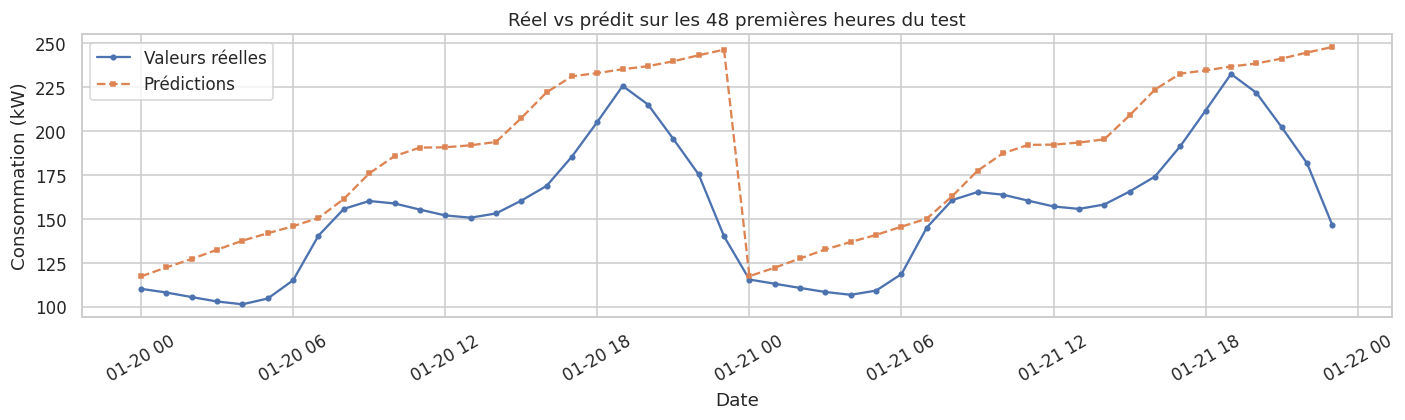

In [19]:
n = 48
plt.figure(figsize=(13, 4))
plt.plot(test["date_heure"].values[:n], y_test.values[:n], label="Valeurs réelles", marker="o", markersize=3)
plt.plot(test["date_heure"].values[:n], y_pred[:n], label="Prédictions", marker="s", markersize=3, linestyle="--")
plt.xlabel("Date")
plt.ylabel("Consommation (kW)")
plt.title("Réel vs prédit sur les 48 premières heures du test")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**Commentaire :** le modèle suit grossièrement le niveau moyen et l'alternance jour / nuit, mais il **lisse** la courbe. Il rate la **montée brutale du matin** (vers 6 h - 8 h), où il prédit beaucoup trop bas (écart allant jusqu'à plus de 130 kW le 25 janvier à 7 h), et il manque le pic du soir. À l'inverse, il **surestime** la consommation en début de nuit (vers 23 h) et l'après-midi. La courbe prédite monte presque en ligne droite de la nuit jusqu'au soir, puis retombe d'un coup à minuit (forme en « dents de scie ») : c'est la signature d'un modèle qui utilise `heure` comme un nombre croissant. Un modèle linéaire ne peut pas représenter le profil réel à deux bosses avec une seule droite en fonction de l'heure.

## Étape 6 : Analyse des limites du modèle linéaire

### 6.1 Résidus en fonction du temps

Heure où le modèle sous-estime le plus : 8 h
Heure où le modèle surestime le plus  : 23 h


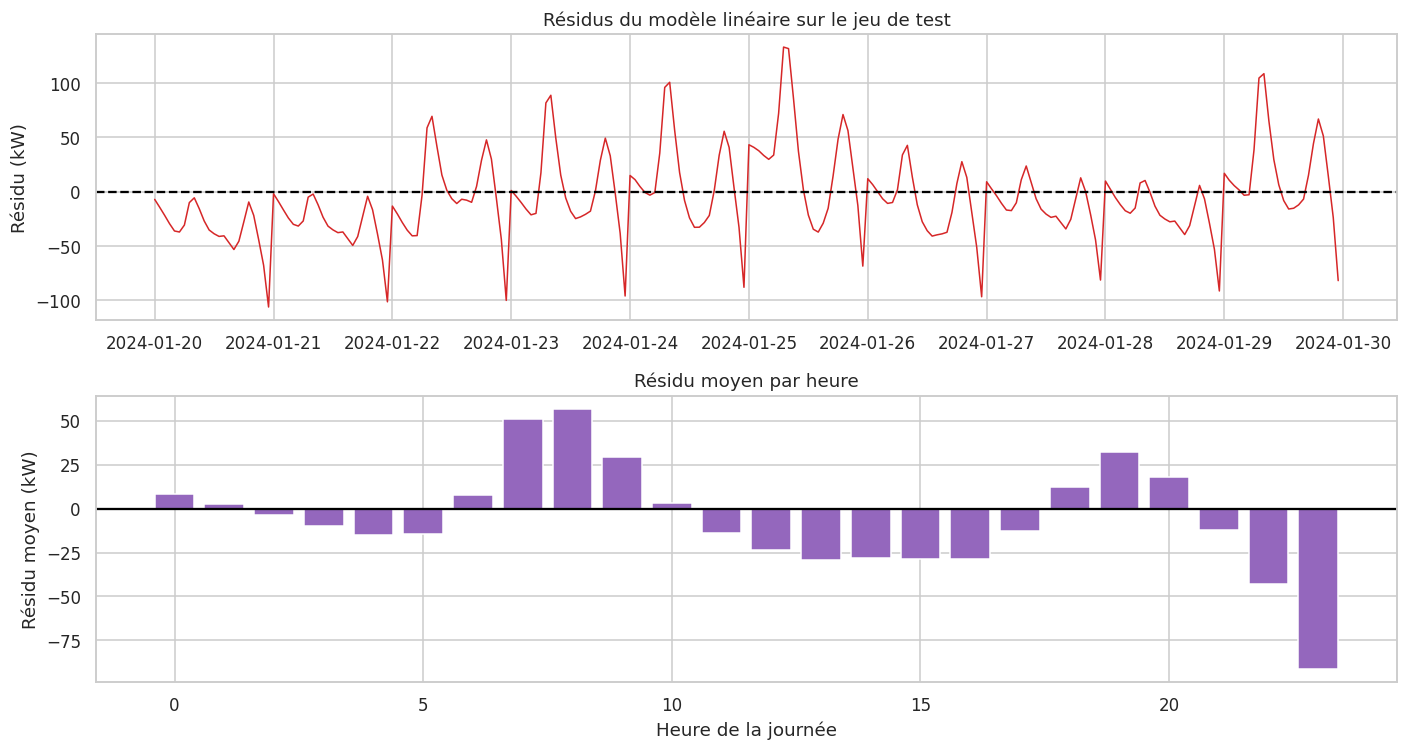

In [20]:
# Résidus = vraie valeur - prédiction
residus = y_test.values - y_pred

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=False)
axes[0].plot(test["date_heure"].values, residus, color="tab:red", linewidth=1)
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set_ylabel("Résidu (kW)")
axes[0].set_title("Résidus du modèle linéaire sur le jeu de test")

# Résidu moyen selon l'heure : met en évidence les erreurs systématiques
residu_par_heure = pd.Series(residus, index=test["heure"].values).groupby(level=0).mean()
axes[1].bar(residu_par_heure.index, residu_par_heure.values, color="tab:purple")
axes[1].axhline(0, color="black")
axes[1].set_xlabel("Heure de la journée")
axes[1].set_ylabel("Résidu moyen (kW)")
axes[1].set_title("Résidu moyen par heure")
plt.tight_layout()
plt.show()

print("Heure où le modèle sous-estime le plus :", residu_par_heure.idxmax(), "h")
print("Heure où le modèle surestime le plus  :", residu_par_heure.idxmin(), "h")

**Y a-t-il des moments où le modèle se trompe systématiquement ?**
Oui. Les résidus ne ressemblent pas à un bruit aléatoire autour de zéro :
- **Sous-estimation** (résidu positif) le **matin entre 7 h et 9 h** (en moyenne +29 à +57 kW) et au **pic de 19 h** (environ +32 kW) ;
- **Surestimation** (résidu négatif) **l'après-midi de 12 h à 17 h** (environ -23 à -29 kW) et surtout **à 23 h** (environ -91 kW : le modèle prédit près de 245 kW alors que la consommation réelle est déjà retombée à 130 - 150 kW) ;
- **Week-end :** le modèle surestime en moyenne la consommation du samedi et du dimanche (environ -24 kW), car il n'a jamais vu de week-end à l'entraînement.

### 6.2 Explications possibles

- **Effet de seuil :** le chauffage ne se déclenche qu'en dessous d'une certaine température. Un modèle linéaire (même avec `temperature2`) représente mal ces changements brusques.
- **Relation non linéaire avec l'heure :** `heure` est utilisée comme un nombre croissant (0 à 23) alors que la consommation suit un cycle qui monte, redescend, remonte (deux pics). Une droite ne peut pas représenter ce profil.
- **Interactions non capturées :** l'effet de la température n'est pas le même la nuit, le jour ou le week-end. Le modèle additionne les effets au lieu de les combiner. De même, `heure` est utilisée comme un nombre croissant (0 à 23) alors que la consommation suit un cycle qui monte puis redescend.
- **Variables manquantes :** humidité, occupation du bâtiment, ensoleillement, jours fériés ou vacances.
- **Peu de données d'entraînement, sans week-end :** l'entraînement couvre cinq jours ouvrés (du lundi 15 au vendredi 19 janvier). Le modèle n'a jamais vu un samedi ou un dimanche, alors que le test en contient (20, 21, 27 et 28 janvier) : il prédit donc pour le week-end comme pour un jour ouvré, d'où des erreurs systématiques ces jours-là.
- **Absence de mémoire :** le modèle ne connaît pas la consommation de l'heure précédente ni de la veille à la même heure.

### 6.3 Conclusion : que faudrait-il améliorer ?

1. **Ajouter des features :** consommation décalée (`lag` 1 h, 24 h, 168 h), moyennes glissantes, encodage cyclique de l'heure (sinus et cosinus), jours fériés, humidité, occupation.
2. **Utiliser un modèle non linéaire :** arbres de décision, forêts aléatoires, gradient boosting (**XGBoost**), qui captent seuils et interactions sans qu'on les code à la main.
3. **Plus de données :** plusieurs mois pour voir plusieurs régimes (semaines, météo variées) et valider avec une validation croisée temporelle (`TimeSeriesSplit`).
4. **Comparer** les résultats avec une référence simple (par exemple la valeur de la veille à la même heure) pour savoir si le modèle apporte vraiment quelque chose.